# Plant Disease Dataset EDA

This notebook explores the `geraldmc/plantvillage-full` dataset for the plant disease detection project. The goal is to confirm the dataset structure, check class balance, understand the train/test split, and inspect a few examples before training a classifier.

Key questions we want to answer:
- What does the dataset look like at a high level?
- Are the classes balanced or heavily skewed?
- Which hosts and crops are represented?
- Do the sample images look consistent enough for model training?


In [19]:
%pip install roboflow dataset pandas matplotlib pillow tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 11.8 MB/s eta 0:00:00


## 1. Load the dataset

The next cell loads the public plant disease dataset from Hugging Face and stores it in a `datasets.DatasetDict` object. This gives us a quick view of the available splits and metadata columns before we flatten it for analysis.


In [35]:
from datasets import load_dataset

ds = load_dataset("geraldmc/plantvillage-full")


## 2. Review the dataset structure

`ds` contains the split structure and column schema. We use the dataset metadata to confirm the labels, image fields, and whether the dataset is already partitioned into train/validation/test subsets.


In [37]:
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
        num_rows: 54304
    })
})

In [38]:
import pandas as pd
from datasets import concatenate_datasets

print(ds)                                   # splits and columns
d = concatenate_datasets(list(ds.values())) # one table; the train/test info is in the "split" column
d.features

DatasetDict({
    train: Dataset({
        features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
        num_rows: 54304
    })
})


{'image': Image(mode=None, decode=True),
 'class_label': Value('string'),
 'class_idx': Value('int32'),
 'host': Value('string'),
 'disease': Value('string'),
 'split': Value('string'),
 'leaf_id': Value('string'),
 'leaf_grouped': Value('bool')}

## 3. Flatten the data for tabular analysis

The dataset is converted into a single pandas table so we can summarize counts, inspect metadata fields, and compute distribution statistics across disease classes and plant hosts.


In [39]:
#metadata only, no images
meta = d.remove_columns("image").to_pandas()
meta.head()

,class_label,class_idx,host,disease,split,leaf_id,leaf_grouped
0,Apple___Apple_scab,0,Apple,Apple scab,test,Apple___Apple_scab::leaf_79,True
1,Apple___Apple_scab,0,Apple,Apple scab,test,Apple___Apple_scab::leaf_19,True
2,Apple___Apple_scab,0,Apple,Apple scab,test,Apple___Apple_scab::leaf_39,True
3,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_25,True
4,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_102,True


In [40]:
len(d)

54304

## 4. Check split composition

This section confirms the overall sample count and how the data is distributed across the available dataset splits. If the split is imbalanced, it will influence model evaluation and training decisions.


In [41]:
meta.split.value_counts()

,count
split,
train,43356
test,10948


In [42]:
meta.groupby("host").agg(images=("class_label","size"),
                               classes=("class_label","nunique"),
                               leaves=("leaf_id","nunique")).sort_values("images")

,images,classes,leaves
host,,,
Raspberry,371,1,37
Blueberry,1502,1,160
Strawberry,1565,2,523
Squash,1835,1,1835
Cherry (including sour),1906,2,175
Potato,2152,3,538
"Pepper, bell",2474,2,857
Peach,2657,2,389
Apple,3171,4,1055


<Axes: title={'center': 'Images per class'}, ylabel='class_label'>

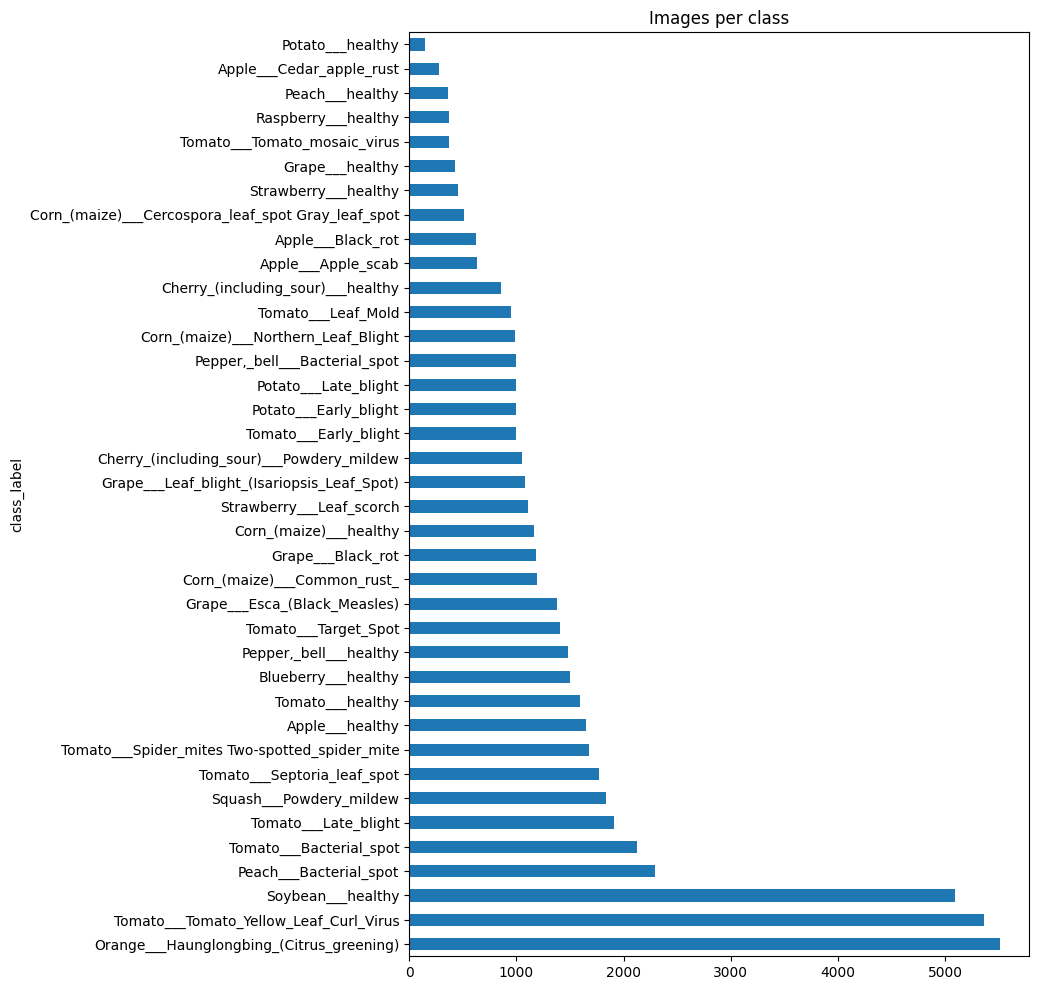

In [43]:
meta.class_label.value_counts().plot(kind="barh", figsize=(8,12), title="Images per class")

## 5. Class distribution and sample review

The next plots show whether certain diseases are much more frequent than others. That matters because class imbalance can bias the model toward majority classes if left untreated.

We also sample a few images from each class to visually confirm that the labels and image quality are consistent for training.


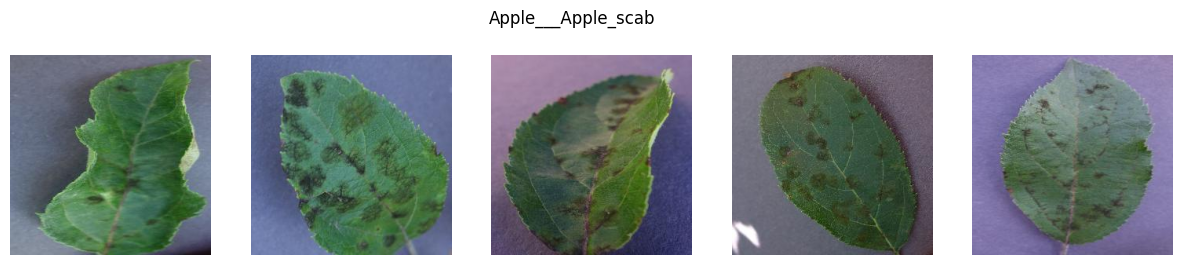

In [46]:
# Sample images per class
import matplotlib.pyplot as plt
def show(label, n=5, seed=0):
    idx = meta.index[meta.class_label == label].to_series().sample(n, random_state=seed)
    fig, ax = plt.subplots(1, n, figsize=(3*n, 3))
    for a, i in zip(ax, idx):
        a.imshow(d[int(i)]["image"]); a.axis("off")
    fig.suptitle(label); plt.show()

show(meta.class_label.iloc[0])